In [15]:
import numpy as np
import matplotlib.pyplot as plt
import numpy.linalg as LA

## Data Generation for Regression (see Lab 1)


In [16]:
def datagen(d, points, m, M, w, sigma):
    X = np.zeros((points,d))
    for i in range(points):
        X[i,:] = np.random.uniform(m, M, d)
    eps = np.random.normal(0, sigma, points)
    y = np.dot(X,w) + eps
    return X, y

In [17]:
# generate multi-dimensional regression dataset
d = 50
w = np.random.normal(0, 1, d)
sigma = 0.1
points = 100
points_test = 100
m = -10
M = 10

X, y = datagen(d, points, m, M, w, sigma)

---

In [18]:
# Thanks to Claude for the pretty animation of gradient descent!

from matplotlib.animation import FuncAnimation
from IPython.display import HTML
plt.rcParams["animation.frame_format"] = "jpeg"

X, y = datagen(2, 200, -10, 10, np.array([1.5, -2.0]), 1.0)
X[:, 1] *= 0.3
n = len(y)
loss   = lambda w: np.mean((y - X @ w) ** 2)
grad   = lambda w: -(2 / n) * X.T @ (y - X @ w)

w_star = np.linalg.solve(X.T @ X, X.T @ y)
lam_max = np.linalg.eigvalsh(2 / n * X.T @ X).max()


def animate_gd(gamma0, iters=40, w0=(1.1, -5.0), schedule=None):
    """schedule(t, gamma0) -> gamma_t  (None = lr costante)"""
    w = np.array(w0, float)
    path, losses = [w.copy()], [loss(w)]
    for t in range(iters):
        gamma0 = gamma0 if schedule is None else schedule(t, gamma0)
        w = w - gamma0 * grad(w)
        path.append(w.copy()); losses.append(loss(w))
    path, losses = np.array(path), np.array(losses)

    # sfondo: curve di livello della loss
    g1 = np.linspace(w_star[0] - 0.6, w_star[0] + 0.6, 150)
    g2 = np.linspace(w_star[1] - 2.2, w_star[1] + 2.2, 150)
    Z = np.array([[loss(np.array([a, b])) for a in g1] for b in g2])

    fig, (ax, axl) = plt.subplots(1, 2, figsize=(22, 9), dpi=90)
    ax.contour(g1, g2, Z, levels=np.geomspace(Z.min() + 1e-2, Z.max(), 18), cmap="viridis")
    ax.plot(*w_star, "r*", ms=15, label=r"$w^*$")
    ax.set_xlim(g1[0], g1[-1]); ax.set_ylim(g2[0], g2[-1])
    ax.set_xlabel(r"$w_1$"); ax.set_ylabel(r"$w_2$"); ax.legend(loc="upper right")
    (trail,) = ax.plot([], [], "o-", c="tab:orange", ms=4, lw=1)
    (head,)  = ax.plot([], [], "o", c="red", ms=8)

    axl.set_xlim(0, iters); axl.set_yscale("log")
    axl.set_ylim(min(losses.min(), loss(w_star)) * 0.7, max(losses[0], 1) * 3)
    axl.set_xlabel("iterazione"); axl.set_ylabel("loss (MSE)"); axl.grid(alpha=0.3)
    (lcurve,) = axl.plot([], [], "o-", c="tab:orange", ms=4)

    def update(k):
        trail.set_data(path[:k + 1, 0], path[:k + 1, 1])
        head.set_data([path[k, 0]], [path[k, 1]])
        lcurve.set_data(np.arange(k + 1), losses[:k + 1])
        fig.suptitle(f"GD  |  step {k}  |  loss = {losses[k]:.3g}")

    anim = FuncAnimation(fig, update, frames=iters + 1, interval=200)
    plt.close(fig)
    return HTML(anim.to_jshtml())

In [22]:
def my_schedule(t, gamma0):
    new_gamma = gamma0 *  0.99
    return new_gamma

animate_gd(gamma0=0.01, iters=100, schedule=my_schedule)

In [23]:
def my_schedule(t, gamma0):
    if t % 10 == 0 and t > 0:
        new_gamma = gamma0 * 0.5
        print(f"Step {t}: learning rate reduced to {new_gamma:.4f}")
        return new_gamma
    else:
        return gamma0
    
animate_gd(gamma0=0.09, iters=100, schedule=my_schedule)

Step 10: learning rate reduced to 0.0450
Step 20: learning rate reduced to 0.0225
Step 30: learning rate reduced to 0.0112
Step 40: learning rate reduced to 0.0056
Step 50: learning rate reduced to 0.0028
Step 60: learning rate reduced to 0.0014
Step 70: learning rate reduced to 0.0007
Step 80: learning rate reduced to 0.0004
Step 90: learning rate reduced to 0.0002


# Regularized Linear and Logistic Regression 

Tasks for this lab:

* Generate linearly separable data with different amount of noise;

* Calculate the Least Square Regression (LSR) solution without or with regularization (Ridge, Lasso and Elastic Net);

* Test which of the three methods achieve better test error.

## Gradient Descent for (Regularized) Linear Regression

Squared error loss and its gradient for **non-regularized linear regression** (see Lab 2):


$$
\mathcal{L}=\frac{1}{n}\|y-Xw\|_{2}^{2},\;\;\;\;\nabla_{w} \mathcal{L} = -\frac{2}{n}X^T(y-Xw)
$$

In [9]:
def SquareLoss(X, y, w):
    points = X.shape[0]
    return (1 / (points)) * LA.norm(y-X@w,2)**2


def OLSGradient(X, y, w, points):
    return (-2 / points) * (X.T @ (y - X @ w))


def GD(X, y, iters, gamma, d):
    W = np.zeros((d,iters))
    L = np.zeros(iters)
    points = X.shape[0]
    w = np.random.normal(0, 0.1, d)
    for i in range(iters):
        W[:,i] = w
        L[i] = SquareLoss(X,y,w)
        w = w - gamma*OLSGradient(X, y, w, points)
    return W, L

In [25]:
# generate multi-dimensional regression dataset
d = 50
w = np.random.normal(0, 1, d)
sigma = 0.1
points = 100
points_test = 100
m = -10
M = 10

X, y = datagen(d, points, m, M, w, sigma)


d = np.shape(X)[1]
iters = 100
gamma = 0.001 

wgd, L = GD(X, y, iters, gamma, d)

wpred = wgd[:,-1]

print('L2 Norm of the Difference Between Ground Truth Weigths and Predicted Weights: ', LA.norm(w-wpred,2))
print(f"w norm={np.linalg.norm(wpred):.4f}")

L2 Norm of the Difference Between Ground Truth Weigths and Predicted Weights:  0.6595181232327303
w norm=5.5500


## Ridge Regression

Some words about regularization

Do you remember the closed form solution for the linear regression? In case you don't...

$$
y=Xw,\;\;\;\; w=X^{-1}y,\;\;\;\;X^{-1}=(X^{T}X)^{-1}X^{T}
$$

$$
w=(X^{T}X)^{-1}X^{T}y
$$

This is really beatuiful...really...[but](https://cdn3.emoji.gg/stickers/2066-nerd-doggo.png) there could be a problem.
This problem is known as

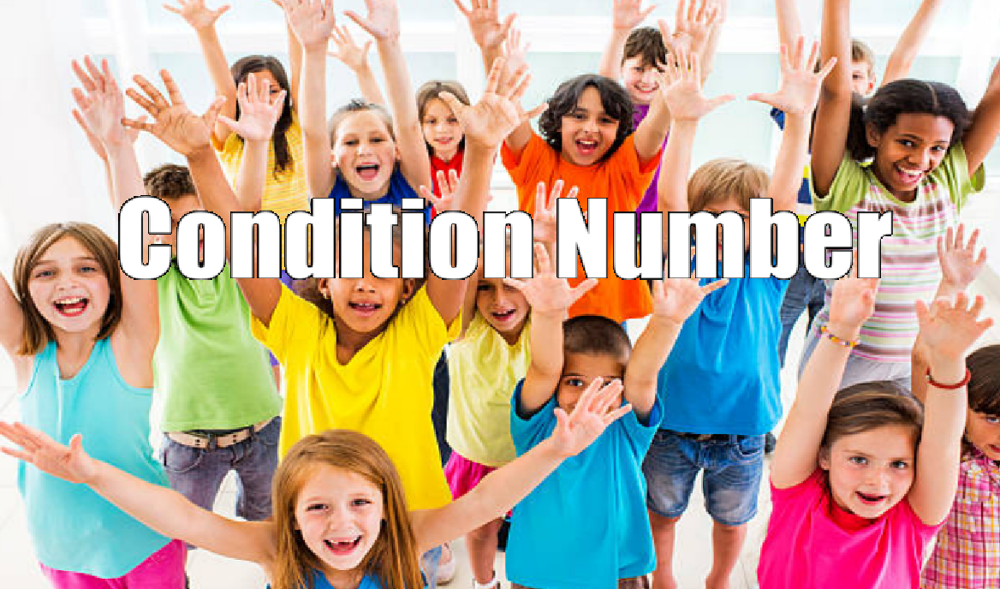

### Small digression on condition number

In [38]:
A = np.array([[1, 1], [1, 1.001]])
b = np.array([2, 2.001])
x = np.linalg.solve(A, b)
(x)

array([1., 1.])

In [47]:
def matrice_mal_condizionata(shape, cond=1e8, seed=10):
    """
    Genera una matrice con numero di condizionamento circa pari a cond.

    Parameters
    ----------
    shape : tuple
        Dimensioni della matrice (n, m).
    cond : float
        Numero di condizionamento desiderato (>= 1).
    seed : int
        Seed per la riproducibilità.
    """
    n, m = shape

    if n == 0 or m == 0:
        raise ValueError("Le dimensioni devono essere positive.")
    if cond < 1:
        raise ValueError("Il numero di condizionamento deve essere >= 1.")

    rng = np.random.default_rng(seed)
    r = min(n, m)

    # Matrici ortonormali
    U, _ = np.linalg.qr(rng.standard_normal((n, r)))
    V, _ = np.linalg.qr(rng.standard_normal((m, r)))

    # Valori singolari dal massimo a 1/cond
    s = np.geomspace(1.0, 1.0 / cond, r)

    # Ricostruzione della matrice
    X = U @ np.diag(s) @ V.T

    return X
X_bad = matrice_mal_condizionata((points, d), cond=1e8, seed=10)

Condition number before regularization:
$$
\boxed{
\kappa_2(X^TX)=
\frac{\lambda_{\max}(X^TX)}
{\lambda_{\min}(X^TX)}
}
$$

In [51]:
#TODO
xtx = X_bad.T @X_bad
cond = LA.eigvalsh(xtx).max()/LA.eigvalsh(xtx).min()
cond

np.float64(9499272211469818.0)

It is provabe (just do some derivatives) that adding the L2 regularization term
$$
\mathcal{L}=\frac{1}{n}\|y-Xw\|_{2}^{2}+\alpha\|w\|_{2}^{2}
$$
is analytically equivalent of solving the linear regression adding an identity matrix when computing $X^TX$

$$
w=(X^{T}X + \alpha I)^{-1}X^{T}y
$$

Condition number after regularization:
$$
\boxed{
\kappa_2(X^TX + \alpha_{reg}I)=
\frac{\lambda_{\max}(X^TX+ \alpha_{reg}I)}
{\lambda_{\min}(X^TX+ \alpha_{reg}I)}
}
$$

In [52]:
#TODO
alpha = 1
xtx = X_bad.T @X_bad + np.eye(d) * alpha
cond = LA.eigvalsh(xtx).max()/LA.eigvalsh(xtx).min()
cond

np.float64(1.9999999999999984)

When do we obtain a ill conditioned matrix? Correlation between features!

In [61]:
#TODO
alpha = 100
new_x = np.column_stack((X, X[:, 0]+ 0.001))
xtx = new_x.T @ new_x
cond = LA.eigvalsh(xtx).max()/LA.eigvalsh(xtx).min()
print(f"bad: {cond}")

xtx = new_x.T @ new_x + np.eye(d+1) * alpha
cond = LA.eigvalsh(xtx).max()/LA.eigvalsh(xtx).min()
cond

bad: 380859760.53143865


np.float64(102.53086515175978)

Squared error loss and its gradient for **Ridge regression**:

$$
\mathcal{L}=\frac{1}{n}\|y-Xw\|_{2}^{2}+\lambda\|w\|_{2}^{2},\;\;\;\;\nabla_{w} \mathcal{L} = -\frac{2}{n}X^T(y-Xw)+2\lambda w
$$

Ridge Regression performs $L2$ regularization, i.e. it minimizes the penalized sum of squares in such a way that smaller $w$ are preferred, indeed the closer the $w$ are to $0$, the smaller is the loss function.

In [65]:
def RidgeSquareLoss(X, y, w, lam):
    """
    Parameters
    ----------
    X : array of float dim n x d
        Matrix containing the dataset
    y : array of float of dim n
        Vector containing the ground truth value of each data point
    w : array of float of dim d
        Weights of the fitted line
    lam : float
        Weight of the L2 penalty term
    """
    #TODO
    points = X.shape[0]
    # Tip: use LA.norm to compute the L2 norm of a vector
    return (LA.norm(y -X @ w)**2 / points +lam *LA.norm(w)**2)


def RidgeGradient(w, lam):
    #TODO
    return 2 * lam *w 

def GDRidge(X, y, iters, gamma, d, lam):
    """
    Parameters
    ----------
    X : array of float dim n x d
        Matrix containing the dataset
    y : array of float of dim n
        Vector containing the ground truth value of each data point
    iter : int
        Number of GD iterations
    gamma : float
        Learning rate
    d : int
        Dimensionality of each data point in the dataset
    lam : float
        Weight of the L2 penalty term
    """
    W = np.zeros((d,iters))
    L = np.zeros(iters)
    points = X.shape[0]
    # w = np.random.normal(0,0.1,d)
    w = np.zeros(d)
    for i in range(iters):
        W[:,i] = w
        #TODO
        w = w - gamma *( OLSgradient(X, Y, w, points) +RidgeGradient(w, lam))
        L[i] = 
    return W, L

In [ ]:
d = np.shape(X)[1]
iters = 100
gamma = 0.001
lam = 0.01

wgdR, L = GDRidge(X, y, iters, gamma, d, lam)
wpredRidge = wgdR[:,-1]
print('L2 Norm of the Difference Between Ground Truth Weigths and Predicted Weights: ', LA.norm(w-wpredRidge,2))
print(f"w norm={np.linalg.norm(wpredRidge):.4f}")

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(L)
plt.title('Loss - Linear scale')
plt.xlabel('Iter')
plt.ylabel('Loss')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(L)
plt.yscale('log')
plt.title('Loss - Log scale')
plt.xlabel('Iter')

plt.ylabel('Loss (log)')
plt.grid(True)

plt.tight_layout()

## Lasso regularization

Squared error loss and its gradient for **Lasso (Least Absolute Shrinkage and Selection Operator) regularization**:

$$
\mathcal{L}=\frac{1}{n}\|y-Xw\|_{2}^{2}+\lambda\|w\|_{1},\;\;\;\;\nabla_{w} \mathcal{L} = -\frac{2}{n}X^T(y-Xw) + ?
$$

This kind of regularization can lead to zero the coefficients, i.e. some of the features of the points could be completely neglected, so it can be used and regareded also as a feature selection strategy.

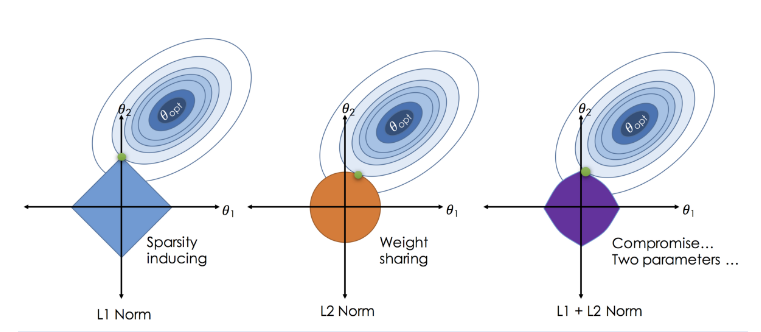

Since we cannot compute the gradient of the penalization term (as it is not differentiable at $0$), we will use **subgradient descent**, that is an algorithm for minimizing a nondifferentialble convex function.

We define the sub-differential of the absolute value function as:

$$
\partial \|w\|_1 = \left\{\begin{matrix}
1 & w>0 \\  
-1 & w<0 \\
[-1, 1] & w=0
\end{matrix}\right.
$$

Hence:

$$
\nabla_{w} \mathcal{L} = -\frac{2}{n}X^T(y-Xw)+\lambda \partial \|w\|_1
$$

In [ ]:
def LassoSquareLoss(X, y, w, lam):
    """
    Parameters
    ----------
    X : array of float dim n x d
        Matrix containing the dataset
    y : array of float of dim n
        Vector containing the ground truth value of each data point
    w : array of float of dim d
        Weights of the fitted line
    lam : float
        Weight of the L1 penalty term
    """
    # TODO
    points = X.shape[0]
    ...
    return loss

def LassoGradient(w, lam):
    # TODO
    return 

In [ ]:
def GDLasso(X, y, iters, gamma, d, lam):
    """
    Parameters
    ----------
    X : array of float dim n x d
        Matrix containing the dataset
    y : array of float of dim n
        Vector containing the ground truth value of each data point
    iter : int
        Number of GD iterations
    gamma : float
        Learning rate
    d : int
        Dimensionality of each data point in the dataset
    lam : float
        Weight of the L1 penalty term
    """
    W = np.zeros((d,iters))
    L = np.zeros(iters)
    w = np.random.normal(0, 0.1, d)
    points = X.shape[0]
    for i in range(iters):
        W[:,i] = w
        #TODO
        w = ...
        L[i] = ...
    return W, L

In [ ]:
d = np.shape(X)[1]
iters = 1000
points = 100
gamma = 0.001
lam = 0.01

wgdL, L = GDLasso(X, y, iters, gamma, points, d, lam)
wpredL = wgdL[:,-1]

print('L2 Norm of the Difference Between Ground Truth Weigths and Predicted Weights: ', LA.norm(w-wpredL,2))
print(f"w norm={np.linalg.norm(wpredL):.4f}")

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(L)
plt.title('Loss - Linear scale')
plt.xlabel('Iter')
plt.ylabel('Loss')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(L)
plt.yscale('log')
plt.title('Loss - Log scale')
plt.xlabel('Iter')

plt.ylabel('Loss (log)')
plt.grid(True)

plt.tight_layout()

## Elastic Net

Regularized regression method that combines the $L1$ and $L2$ penalties of the Lasso and Ridge methods, respectively, to get the best of both words.
The loss function to minimize is defined as:

$$
L=\frac{1}{n}\|y-Xw\|_{2}^{2}+\lambda_1\|w\|_{1} + \lambda_2 \|w\|_2
$$

Hence in this problem we have $2$ parameters to tune.

We can rewrite the problem as follows, so that we have only $1$ parameter $\lambda$ to tune (i.e. as a convex combination of Ridge and Lasso penalties):

$$
L=\frac{1}{n}\|y-Xw\|_{2}^{2}+(\lambda_r) \cdot \|w\|_{1} + (1 - \lambda_r) \cdot \|w\|_2
$$

where $\lambda_r$, which is provided in input, is the _importance_ given to the $L1$ penalty (the opposite is also possible).

In [ ]:
# TODO

---

### Let's see some performances

In [70]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error

In [74]:
# Create a regression dataset with many correlated features and noise
X, y = make_regression(
    n_samples=1000,
    n_features=15,
    n_informative=5,
    noise=25,
    effective_rank=14
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

In [72]:
lam = 0.1  # Regularization strength

# Define some models
LinReg = LinearRegression()
RidgeReg = Ridge(alpha=lam)
LassoReg = Lasso(alpha=lam)
ElasticNetReg = ElasticNet(alpha=lam, l1_ratio=0.5)


In [81]:
# TODO: Fit the models
# Tips: Use the .fit() method
LinReg.fit(X_train,y_train)
RidgeReg.fit(X_train,y_train)
LassoReg.fit(X_train,y_train)
ElasticNetReg.fit(X_train,y_train)
# TODO: Predict on the test set
# Tips: I don't think it is needed
y_lin = LinReg.predict(X_test)
y_ridge = RidgeReg.predict(X_test)
y_lasso = LassoReg.predict(X_test)
y_elastic = ElasticNetReg.predict(X_test)



In [84]:
# TODO: Compute the mean squared error for each model
mse_lin = mean_squared_error(y_test, y_lin)
mse_ridge = mean_squared_error(y_test, y_ridge)
mse_lasso= mean_squared_error(y_test, y_lasso)
mse_elastic = mean_squared_error(y_test, y_elastic)

print(f"Mean Squared Error (Linear Regression): {mse_lin:.4f}")
print(f"Mean Squared Error (Ridge Regression): {mse_ridge:.4f}")
print(f"Mean Squared Error (Lasso Regression): {mse_lasso:.4f}")
print(f"Mean Squared Error (Elastic Net Regression): {mse_elastic:.4f}")

Mean Squared Error (Linear Regression): 604.2318
Mean Squared Error (Ridge Regression): 598.0172
Mean Squared Error (Lasso Regression): 596.3529
Mean Squared Error (Elastic Net Regression): 596.3529


### Now, let's see the effects of the regularization

In [86]:
coefs_lin = LinReg.coef__

plt.bar(np.arange(len(coefs_lin)) - 0.3, coefs_lin, width=0.2, label='Linear', alpha=0.7)
plt.bar(np.arange(len(coefs_ridge)) - 0.1, coefs_ridge, width=0.2, label='Ridge', alpha=0.7)
plt.bar(np.arange(len(coefs_lasso)) + 0.1, coefs_lasso, width=0.2, label='Lasso', alpha=0.7)
plt.bar(np.arange(len(coefs_elastic)) + 0.3, coefs_elastic, width=0.2, label='Elastic Net', alpha=0.7)
plt.xlabel('Feature Index')
plt.ylabel('Coefficient Value')
plt.legend()
plt.title('Comparison of Coefficients')

NameError: name 'coefs_lin' is not defined

---

In [ ]:
from scipy.optimize import minimize

# Variants

## Structured Regularization Methods

Let $\mathcal{L}(\boldsymbol{\beta})$ denote the empirical loss. Structured regularization incorporates prior knowledge about relationships among features.

### 1. Group LASSO
$
\min_{\boldsymbol{\beta}}\;
\mathcal{L}(\boldsymbol{\beta})
+\lambda\sum_{g=1}^{G}w_g\|\boldsymbol{\beta}_g\|_2
$

Selects entire groups of features jointly, setting all coefficients in a group to zero or retaining the group. Useful for categorical variables, feature families, and multi-task learning.

Paper: [Yuan & Lin (2006)](https://doi.org/10.1111/j.1467-9868.2005.00532.x).

### 2. Sparse Group LASSO
$
\min_{\boldsymbol{\beta}}\;
\mathcal{L}(\boldsymbol{\beta})
+\lambda_1\|\boldsymbol{\beta}\|_1
+\lambda_2\sum_g w_g\|\boldsymbol{\beta}_g\|_2
$

Combines group-level selection with individual feature selection within each group.

Paper: [Simon et al. (2013)](https://doi.org/10.1214/13-AOAS627).

### 3. Fused LASSO
$
\min_{\boldsymbol{\beta}}\;
\mathcal{L}(\boldsymbol{\beta})
+\lambda_1\|\boldsymbol{\beta}\|_1
+\lambda_2\sum_{j=2}^{p}|\beta_j-\beta_{j-1}|
$

Encourages both sparse coefficients and similar coefficients for adjacent features. Useful for ordered variables, time series, and genomic data.

Paper: [Tibshirani et al. (2005)](https://doi.org/10.1111/j.1467-9868.2005.00490.x).


### Group lasso

---

# Time to play

In [67]:
X, y = make_regression(
    n_samples=1000,
    n_features=15,
    n_informative=5,
    noise=25,
    effective_rank=14
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

NameError: name 'make_regression' is not defined

In [ ]:
class CustomRegressor:
    def __init__(self, reg_function,lam=0.01):
        self.lam = lam
        self.coef_ = None
        self.reg_function = reg_function

    def fit(self, X, y):
        n_samples, n_features = X.shape

        def objective(weights):
            residuals = y - X @ weights
            data_loss = np.sum(residuals**2) / (n_samples)
            return data_loss + self.lam * self.reg_function(weights)

        initial_weights = np.zeros(n_features)
        result = minimize(objective, initial_weights, method='BFGS')
        if not result.success:
                print("Attenzione:", result.message)
        self.coef_ = result.x

    def predict(self, X):
        return X @ self.coef_
    

In [ ]:
def my_reg(weights):
      
    return np.sum(weights)

my_regressor = CustomRegressor(lam=0.01, reg_function=my_reg)
my_regressor.fit(X_train, y_train)
y_pred = my_regressor.predict(X_test)

mse_custom = mean_squared_error(y_test, y_pred)
mse_custom

---

# Exam-like questions

- Why Lasso does variable selection?
- Explain the concept of pseudogradient for Lasso Regularization